<a href="https://colab.research.google.com/github/DOHA-BASEM3/DS330-Deep-Learning-Project/blob/main/GOOD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Description

**Dataset Name:** Combined Cycle Power Plant (CCPP)

**Source:** UCI Machine Learning Repository

**Dataset Link:** https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

**Dataset Type:** Tabular Data – Supervised Learning – Regression

**Dataset Size:** 9,568 rows and 4 input features

**Features:**
- **AT:** Ambient Temperature
- **V:** Exhaust Vacuum
- **AP:** Ambient Pressure
- **RH:** Relative Humidity

**Target Variable:**
- **PE:** Net Hourly Electrical Energy Output (MW)

**Problem Definition:** Train a deep neural network to predict the electrical power output (PE) using four environmental and operational input features.

**Why This Dataset?** It meets the project's regression requirements, contains continuous numerical features and a continuous target, and is suitable for comparing linear regression with deep neural networks.

# **Dataset Loading**

In [3]:
%pip install -q ucimlrepo

In [4]:

# Import libraries
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from ucimlrepo import fetch_ucirepo

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load dataset
power_plant = fetch_ucirepo(id=294)
X = power_plant.data.features.copy()
y = power_plant.data.targets.copy()
df = pd.concat([X, y], axis=1)

# Inspect dataset
print("Dataset shape:", df.shape)
print("Features:", X.columns.tolist())
print("Target:", y.columns.tolist())
display(df.head())


Using device: cpu
Dataset shape: (9568, 5)
Features: ['AT', 'V', 'AP', 'RH']
Target: ['PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


# **Data  Quality Assessment**

In [5]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())


Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41

Data types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


# **Data Preprocessing**

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df[['PE']].copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (9527, 5)
Remaining duplicate rows: 0


# **Train / Validation / Test Split**

In [7]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Display dataset split shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)


Training set: (6668, 4) (6668, 1)
Validation set: (1429, 4) (1429, 1)
Test set: (1430, 4) (1430, 1)


# **Exploratory Data Analysis (EDA)**

أجرينا التحليل الاستكشافي بعد تقسيم البيانات حتى نحلل بيانات التدريب فقط، ونتجنب استخدام معلومات من بيانات الاختبار أثناء تطوير النموذج. وهذا يساعد على منع تسريب البيانات وضمان تقييم نهائي عادل.

In [8]:
# Correlation analysis
display(X_train.join(y_train).corr().round(2))


,AT,V,AP,RH,PE
AT,1.00,0.84,-0.50,-0.54,-0.95
V,0.84,1.00,-0.40,-0.30,-0.87
AP,-0.50,-0.40,1.00,0.09,0.52
RH,-0.54,-0.30,0.09,1.00,0.39
PE,-0.95,-0.87,0.52,0.39,1.00


أهم نتيجة: درجة الحرارة هي الأكثر ارتباطًا بالطاقة الكهربائية الناتجة من بين الخصائص الأربع، وفق معامل ارتباط بيرسون.

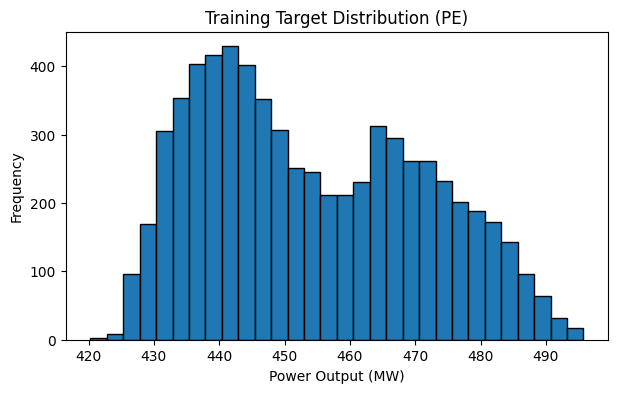

In [9]:

# Target distribution
plt.figure(figsize=(7, 4))
plt.hist(y_train["PE"], bins=30, edgecolor="black")
plt.xlabel("Power Output (MW)")
plt.ylabel("Frequency")
plt.title("Training Target Distribution (PE)")
plt.show()


. هل النتائج مفيدة للمشروع؟
نعم، لسببين:
- توضح أن المتغير الهدف يحتوي على قيم رقمية مستمرة ومتنوعة، وهذا مناسب لمشكلة الانحدار.
- تساعدنا نفهم طبيعة القيم التي سيتعلم النموذج التنبؤ بها.

الكود يعرض توزيع البيانات فقط، ولا يغيّر أي قيمة أو يؤثر على تدريب النموذج.

# **Feature Standardization**

In [10]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform all sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


print("Training mean:", X_train_scaled.mean(axis=0))
print("Training std:", X_train_scaled.std(axis=0))


Training set: (6668, 4)
Validation set: (1429, 4)
Test set: (1430, 4)
Training mean: [-3.18081894e-16  1.49983338e-16 -1.50995659e-15 -2.05660990e-16]
Training std: [1. 1. 1. 1.]


In [11]:

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))


Training: 6668
Validation: 1429


# **Linear Regression Baseline**

In [12]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Train linear regression baseline
start_time = time.perf_counter()
linear_model = LinearRegression().fit(X_train_scaled, y_train)
linear_training_time = time.perf_counter() - start_time

# Evaluate on training and validation sets
linear_train_mse = mean_squared_error(
    y_train, linear_model.predict(X_train_scaled)
)
linear_val_mse = mean_squared_error(
    y_val, linear_model.predict(X_val_scaled)
)

print(f"Training MSE: {linear_train_mse:.4f}")
print(f"Validation MSE: {linear_val_mse:.4f}")
print(f"Training Time: {linear_training_time:.2f} seconds")


Training MSE: 20.2748
Validation MSE: 21.4396
Training Time: 0.03 seconds


# **Baseline Deep Neural Network**

In [13]:

# Baseline hyperparameters
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cpu")

hidden_layers = [64, 32]
learning_rate = 0.001
batch_size = 32
epochs = 100

# DataLoader
generator = torch.Generator().manual_seed(42)
train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, generator=generator
)

# Build neural network
model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Training
train_losses, val_losses = [], []
start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        train_loss = criterion(model(X_train_tensor), y_train_tensor).item()
        val_loss = criterion(model(X_val_tensor), y_val_tensor).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

training_time = time.perf_counter() - start_time

nn_train_mse = train_losses[-1]
nn_val_mse = val_losses[-1]
improvement = (linear_val_mse - nn_val_mse) / linear_val_mse * 100

print(f"Training MSE: {nn_train_mse:.4f}")
print(f"Validation MSE: {nn_val_mse:.4f}")
print(f"Training Time: {training_time:.4f} seconds")
print(f"Improvement over Linear Regression: {improvement:.2f}%")



Training MSE: 16.7957
Validation MSE: 18.6084
Training Time: 51.6657 seconds
Improvement over Linear Regression: 13.21%


In [14]:

# Baseline model comparison
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Deep Neural Network"],
    "Training MSE": [linear_train_mse, nn_train_mse],
    "Validation MSE": [linear_val_mse, nn_val_mse],
    "Training Time (s)": [linear_training_time, training_time],
    "Improvement (%)": [0, improvement]
})

display(comparison_df.style.format({
    "Training MSE": "{:.4f}",
    "Validation MSE": "{:.4f}",
    "Training Time (s)": "{:.2f}",
    "Improvement (%)": "{:.2f}%"
}))


,Model,Training MSE,Validation MSE,Training Time (s),Improvement (%)
0,Linear Regression,20.2748,21.4396,0.03,0.00%
1,Deep Neural Network,16.7957,18.6084,51.67,13.21%


# **Hyperparameter Experiments**

## <font color="#3B82F6">Learning Rate</font>



### Learning Rate Experiments — Results Summary

In [15]:

# Learning Rate Experiments
learning_rates = [0.0001, 0.0003, 0.0005, 0.002, 0.003, 0.01, 0.03]
lr_results = []

for lr in learning_rates:
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        train_dataset, batch_size=32,
        shuffle=True, generator=generator
    )

    model = nn.Sequential(
        nn.Linear(4, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_losses, val_losses = [], []
    start = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_losses.append(loss_fn(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item())

            val_losses.append(loss_fn(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item())

    lr_results.append({
        "Learning Rate": lr,
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": time.perf_counter() - start,
        "Train Losses": train_losses,
        "Val Losses": val_losses
    })


In [16]:

# Learning Rate Results Summary
lr_df = pd.DataFrame(lr_results)

baseline_row = pd.DataFrame([{
    "Run": "Baseline",
    "Learning Rate": 0.001,
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": training_time
}])

experiment_rows = lr_df[[
    "Learning Rate", "Train MSE", "Val MSE", "Time (s)"
]].copy()

experiment_rows.insert(
    0, "Run",
    [f"LR Experiment {i}" for i in range(1, len(lr_df) + 1)]
)

lr_summary = pd.concat(
    [baseline_row, experiment_rows], ignore_index=True
)

display(lr_summary.style.format({
    "Learning Rate": "{:.4f}",
    "Train MSE": "{:.4f}",
    "Val MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}))

best_lr = lr_summary.loc[lr_summary["Val MSE"].idxmin()]

print(f"Best Learning Rate: {best_lr['Learning Rate']:.4f}")
print(f"Lowest Validation MSE: {best_lr['Val MSE']:.4f}")


,Run,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,0.0010,16.7957,18.6084,51.67
1,LR Experiment 1,0.0001,31.7889,31.3234,34.76
2,LR Experiment 2,0.0003,17.4802,19.0203,33.32
3,LR Experiment 3,0.0005,17.5269,19.1729,32.50
4,LR Experiment 4,0.0020,16.5886,18.2036,34.08
5,LR Experiment 5,0.0030,17.2582,19.1169,33.29
6,LR Experiment 6,0.0100,21.0044,23.7329,33.16
7,LR Experiment 7,0.0300,31.6638,35.6667,32.19


Best Learning Rate: 0.0020
Lowest Validation MSE: 18.2036


## <font color="#3B82F6">Optimizer </font>

In [17]:

# Optimizer Experiments
optimizer_settings = [
    ("SGD", 0.001, 0.0),
    ("SGD + Momentum", 0.001, 0.9),
    ("SGD", 0.00001, 0.0),
    ("SGD + Momentum", 0.00001, 0.9),
    ("SGD", 0.002, 0.0),
]

optimizer_results = []

X_train_dev = X_train_tensor.to(device)
y_train_dev = y_train_tensor.to(device)
X_val_dev = X_val_tensor.to(device)
y_val_dev = y_val_tensor.to(device)

for name, lr, momentum in optimizer_settings:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset, batch_size=32,
        shuffle=True, generator=generator
    )

    model = nn.Sequential(
        nn.Linear(4, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    optimizer = torch.optim.SGD(
        model.parameters(), lr=lr, momentum=momentum
    )

    criterion = nn.MSELoss()
    train_losses, val_losses = [], []
    start = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_mse = criterion(model(X_train_dev), y_train_dev).item()
            val_mse = criterion(model(X_val_dev), y_val_dev).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    optimizer_results.append({
        "Optimizer": name,
        "Learning Rate": lr,
        "Momentum": momentum,
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": time.perf_counter() - start,
        "Epochs": len(train_losses),
        "Status": "Valid" if np.isfinite(train_mse) and np.isfinite(val_mse) else "Failed",
        "Train Losses": train_losses,
        "Val Losses": val_losses
    })


In [18]:

# Optimizer Results Summary
optimizer_summary = pd.DataFrame([{
    "Optimizer": "Adam",
    "Learning Rate": 0.001,
    "Momentum": np.nan,
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": training_time,
    "Epochs": 100,
    "Status": "Valid"
}] + [{k: v for k, v in r.items()
      if k not in ["Train Losses", "Val Losses"]}
     for r in optimizer_results])

optimizer_summary.insert(0, "Run",
    ["Baseline"] + [f"Experiment {i}" for i in range(1, len(optimizer_results) + 1)]
)

display(optimizer_summary.style.format({
    "Learning Rate": "{:.5f}",
    "Momentum": "{:.1f}",
    "Train MSE": "{:.4f}",
    "Val MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}, na_rep="—"))

best = optimizer_summary.loc[optimizer_summary["Val MSE"].idxmin()]
print(f"Best: {best['Optimizer']} | LR: {best['Learning Rate']:.5f} | Val MSE: {best['Val MSE']:.4f}")


,Run,Optimizer,Learning Rate,Momentum,Train MSE,Val MSE,Time (s),Epochs,Status
0,Baseline,Adam,0.00100,—,16.7957,18.6084,51.67,100,Valid
1,Experiment 1,SGD,0.00100,0.0,—,—,0.20,1,Failed
2,Experiment 2,SGD + Momentum,0.00100,0.9,—,—,0.23,1,Failed
3,Experiment 3,SGD,0.00001,0.0,17.3211,18.8810,23.32,100,Valid
4,Experiment 4,SGD + Momentum,0.00001,0.9,16.3380,18.0177,24.56,100,Valid
5,Experiment 5,SGD,0.00200,0.0,—,—,0.29,1,Failed


Best: SGD + Momentum | LR: 0.00001 | Val MSE: 18.0177


## <font color="#3B82F6">Batch Size</font>


In [19]:

# Batch Size Experiments
batch_sizes = [16, 24, 64, 128, 256]
batch_results = []

for bs in batch_sizes:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset, batch_size=bs,
        shuffle=True, generator=generator
    )

    model = nn.Sequential(
        nn.Linear(4, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()
    train_losses, val_losses = [], []
    start = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()
            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    batch_results.append({
        "Batch Size": bs,
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": time.perf_counter() - start,
        "Epochs": len(train_losses),
        "Train Losses": train_losses,
        "Val Losses": val_losses
    })


In [20]:

# Batch Size Results Summary
batch_df = pd.DataFrame(batch_results).drop(
    columns=["Train Losses", "Val Losses"]
)

batch_df.insert(0, "Run", [
    f"Experiment {i}" for i in range(1, len(batch_df) + 1)
])

batch_df.loc[len(batch_df)] = [
    "Baseline", 32, nn_train_mse, nn_val_mse, training_time, 100
]

batch_df = batch_df.sort_values("Batch Size").reset_index(drop=True)

display(batch_df.style.format({
    "Train MSE": "{:.4f}",
    "Val MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}))


,Run,Batch Size,Train MSE,Val MSE,Time (s),Epochs
0,Experiment 1,16,18.5267,20.3375,58.36,100
1,Experiment 2,24,16.6223,18.3728,40.58,100
2,Baseline,32,16.7957,18.6084,51.67,100
3,Experiment 3,64,17.8586,19.4846,18.70,100
4,Experiment 4,128,21.7127,22.2300,12.53,100
5,Experiment 5,256,138.2894,132.3394,9.31,100


## <font color="#3B82F6">Depth and Width</font>


In [21]:

# Architecture Experiments
architectures = [
    [32, 32],
    [128, 32],
    [64, 64],
    [64, 16],
    [64],
    [64, 32, 16],
    [64, 32, 8],
    [64, 32, 16, 8]
]

architecture_results = []

for hidden_layers in architectures:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        train_dataset, batch_size=32,
        shuffle=True, generator=generator
    )

    layers = []
    input_size = 4

    for neurons in hidden_layers:
        layers.extend([nn.Linear(input_size, neurons), nn.ReLU()])
        input_size = neurons

    model = nn.Sequential(*layers, nn.Linear(input_size, 1)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    start = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

    architecture_results.append({
        "Architecture": str(hidden_layers),
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": time.perf_counter() - start,
        "Epochs": 100,
        "Train Losses": train_losses,
        "Val Losses": val_losses
    })


In [22]:

# Architecture Results Summary
architecture_summary = pd.DataFrame(architecture_results).drop(
    columns=["Train Losses", "Val Losses"]
)

architecture_summary.insert(
    0, "Run",
    [f"Experiment {i}" for i in range(1, len(architecture_summary) + 1)]
)

baseline = pd.DataFrame([{
    "Run": "Baseline",
    "Architecture": "[64, 32]",
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": training_time,
    "Epochs": 100
}])

architecture_summary = pd.concat(
    [baseline, architecture_summary], ignore_index=True
)

display(architecture_summary.style.format({
    "Train MSE": "{:.4f}",
    "Val MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}, na_rep="—"))

best_arch = architecture_summary.loc[
    architecture_summary["Val MSE"].idxmin()
]

print("Best Architecture:", best_arch["Architecture"])
print(f"Lowest Validation MSE: {best_arch['Val MSE']:.4f}")


,Run,Architecture,Train MSE,Val MSE,Time (s),Epochs
0,Baseline,"[64, 32]",16.7957,18.6084,51.67,100
1,Experiment 1,"[32, 32]",18.4073,19.9251,30.62,100
2,Experiment 2,"[128, 32]",16.1573,17.9696,32.84,100
3,Experiment 3,"[64, 64]",16.5616,18.3218,33.22,100
4,Experiment 4,"[64, 16]",17.4270,19.2471,30.99,100
5,Experiment 5,[64],18.4714,19.4936,26.21,100
6,Experiment 6,"[64, 32, 16]",16.1674,17.9470,37.27,100
7,Experiment 7,"[64, 32, 8]",16.5627,18.3147,36.47,100
8,Experiment 8,"[64, 32, 16, 8]",16.1852,18.0899,42.19,100


Best Architecture: [64, 32, 16]
Lowest Validation MSE: 17.9470


## <font color="#3B82F6">Loss Function</font>


In [33]:

# Loss Function Experiments
loss_settings = [
    ("L1", None),
    ("Huber", 1),
    ("Huber", 4),
    ("Huber", 8),
    ("Huber", 16)
]

loss_results = []

for name, delta in loss_settings:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset, batch_size=32,
        shuffle=True, generator=generator
    )

    model = nn.Sequential(
        nn.Linear(4, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    loss_fn = nn.L1Loss() if name == "L1" else nn.HuberLoss(delta=delta)
    mse = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_losses, val_losses = [], []
    start = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_mse = mse(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = mse(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

    loss_results.append({
        "Training Loss": name,
        "Delta": delta,
        "Train MSE": train_losses[-1],
        "Validation MSE": val_losses[-1],
        "Time (s)": time.perf_counter() - start,
        "Train Losses": train_losses,
        "Val Losses": val_losses
    })


In [35]:
# Loss Function Results Summary

loss_summary = pd.DataFrame(loss_results).drop(
    columns=["Train Losses", "Val Losses"]
)

loss_summary.insert(0, "Run", [
    f"Experiment {i}" for i in range(1, len(loss_summary) + 1)
])

baseline = {
    "Run": "Baseline",
    "Training Loss": "MSE",
    "Delta": np.nan,
    "Train MSE": nn_train_mse,
    "Validation MSE": nn_val_mse,
    "Time (s)": training_time
}
loss_summary = pd.DataFrame(
    [baseline, *loss_summary.to_dict("records")]
)

display(loss_summary.style.format({
    "Delta": "{:.0f}",
    "Train MSE": "{:.4f}",
    "Validation MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}, na_rep="—"))

best_loss = loss_summary.loc[
    loss_summary["Validation MSE"].idxmin()
]

print("Best Training Loss:", best_loss["Training Loss"])
print(f"Lowest Validation MSE: {best_loss['Validation MSE']:.4f}")

,Run,Training Loss,Delta,Train MSE,Validation MSE,Time (s)
0,Baseline,MSE,—,16.7957,18.6084,51.67
1,Experiment 1,L1,—,19.2859,21.0570,38.15
2,Experiment 2,Huber,1,19.4388,21.1215,31.72
3,Experiment 3,Huber,4,17.6375,19.3618,31.74
4,Experiment 4,Huber,8,16.9638,18.6934,33.09
5,Experiment 5,Huber,16,17.0982,18.8006,33.08


Best Training Loss: MSE
Lowest Validation MSE: 18.6084


# **Experiment Results Table**

In [36]:

# Final Experiment Results Table
rows = [
    ["Linear Regression", "Baseline", "Linear Regression",
     linear_train_mse, linear_val_mse, linear_training_time],
    ["Baseline NN", "Baseline", "Adam, LR=0.001, [64, 32], BS=32",
     nn_train_mse, nn_val_mse, training_time]
]

groups = [
    ("Learning Rate", lr_results, "Learning Rate"),
    ("Optimizer", optimizer_results, "Optimizer"),
    ("Batch Size", batch_results, "Batch Size"),
    ("Depth & Width", architecture_results, "Architecture"),
    ("Loss Function", loss_results, "Training Loss")
]

for topic, results, setting in groups:
    for i, r in enumerate(results, 1):
        config = str(r[setting])

        if topic == "Optimizer":
            config += f", LR={r['Learning Rate']:.5f}, Momentum={r['Momentum']}"
        elif topic == "Loss Function" and r["Delta"] is not None:
            config += f", Delta={r['Delta']}"

        rows.append([
            f"Experiment {i}", topic, config,
            r["Train MSE"], r["Val MSE"] if "Val MSE" in r else r["Validation MSE"],
            r["Time (s)"]
        ])

all_results_table = pd.DataFrame(rows, columns=[
    "Run", "Topic", "Configuration",
    "Train MSE", "Val MSE", "Time (s)"
])

all_results_table["Status"] = np.where(
    np.isfinite(all_results_table["Train MSE"]) &
    np.isfinite(all_results_table["Val MSE"]),
    "Valid", "Failed"
)

display(all_results_table.style.format({
    "Train MSE": "{:.4f}",
    "Val MSE": "{:.4f}",
    "Time (s)": "{:.2f}"
}, na_rep="—"))

print("\nExperiments per topic:")
print(all_results_table.query("Topic != 'Baseline'")["Topic"].value_counts())
print("\nTotal Experiments:",
      (all_results_table["Topic"] != "Baseline").sum())


,Run,Topic,Configuration,Train MSE,Val MSE,Time (s),Status
0,Linear Regression,Baseline,Linear Regression,20.2748,21.4396,0.03,Valid
1,Baseline NN,Baseline,"Adam, LR=0.001, [64, 32], BS=32",16.7957,18.6084,51.67,Valid
2,Experiment 1,Learning Rate,0.0001,31.7889,31.3234,34.76,Valid
3,Experiment 2,Learning Rate,0.0003,17.4802,19.0203,33.32,Valid
4,Experiment 3,Learning Rate,0.0005,17.5269,19.1729,32.50,Valid
5,Experiment 4,Learning Rate,0.002,16.5886,18.2036,34.08,Valid
6,Experiment 5,Learning Rate,0.003,17.2582,19.1169,33.29,Valid
7,Experiment 6,Learning Rate,0.01,21.0044,23.7329,33.16,Valid
8,Experiment 7,Learning Rate,0.03,31.6638,35.6667,32.19,Valid
9,Experiment 1,Optimizer,"SGD, LR=0.00100, Momentum=0.0",—,—,0.20,Failed



Experiments per topic:
Topic
Depth & Width    8
Learning Rate    7
Optimizer        5
Batch Size       5
Loss Function    5
Name: count, dtype: int64

Total Experiments: 30


# **Best Model Selection**


In [37]:

# Best Model Selection
valid_results = all_results_table[
    (all_results_table["Topic"] != "Baseline") &
    np.isfinite(all_results_table["Val MSE"])
]

best_row = valid_results.loc[valid_results["Val MSE"].idxmin()]

improvement = (
    (linear_val_mse - best_row["Val MSE"]) / linear_val_mse
) * 100

print("Best Model Selection")
print(f"Topic: {best_row['Topic']}")
print(f"Run: {best_row['Run']}")
print(f"Configuration: {best_row['Configuration']}")
print(f"Training MSE: {best_row['Train MSE']:.4f}")
print(f"Validation MSE: {best_row['Val MSE']:.4f}")
print(f"Improvement over Linear Regression: {improvement:.2f}%")


Best Model Selection
Topic: Depth & Width
Run: Experiment 6
Configuration: [64, 32, 16]
Training MSE: 16.1674
Validation MSE: 17.9470
Improvement over Linear Regression: 16.29%


# **Final Test Evaluation**

In [27]:

# Rebuild and Train Best Model
torch.manual_seed(42)

generator = torch.Generator().manual_seed(42)
best_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, generator=generator
)

best_model = nn.Sequential(
    nn.Linear(4, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1)
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(best_model.parameters(), lr=0.001)

best_train_losses, best_val_losses = [], []
start = time.perf_counter()

for epoch in range(100):
    best_model.train()

    for xb, yb in best_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(best_model(xb), yb)
        loss.backward()
        optimizer.step()

    best_model.eval()
    with torch.no_grad():
        train_mse = criterion(
            best_model(X_train_tensor.to(device)),
            y_train_tensor.to(device)
        ).item()

        val_mse = criterion(
            best_model(X_val_tensor.to(device)),
            y_val_tensor.to(device)
        ).item()

    best_train_losses.append(train_mse)
    best_val_losses.append(val_mse)

best_training_time = time.perf_counter() - start
best_val_mse = best_val_losses[-1]

print("Selected Architecture: [64, 32, 16]")
print(f"Training MSE: {best_train_losses[-1]:.4f}")
print(f"Validation MSE: {best_val_mse:.4f}")
print(f"Training Time: {best_training_time:.2f} seconds")
print("Epochs Completed: 100")


Selected Architecture: [64, 32, 16]
Training MSE: 16.1674
Validation MSE: 17.9470
Training Time: 36.89 seconds
Epochs Completed: 100


In [28]:

# Final Test Evaluation — Run Once
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).to(device)

best_model.eval()
with torch.no_grad():
    test_predictions = best_model(X_test_tensor)
    test_mse = nn.MSELoss()(test_predictions, y_test_tensor).item()

print("Final Test Evaluation")
print("Best Architecture: [64, 32, 16]")
print(f"Validation MSE: {best_val_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")
print(f"Test RMSE: {np.sqrt(test_mse):.4f}")


Final Test Evaluation
Best Architecture: [64, 32, 16]
Validation MSE: 17.9470
Test MSE: 18.5319
Test RMSE: 4.3049


# **Final Model Comparison**


In [29]:

# Final Model Comparison
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Baseline Neural Network",
        "Best Neural Network [64, 32, 16]"
    ],
    "Val MSE": [linear_val_mse, nn_val_mse, best_val_mse],
    "Test MSE": [np.nan, np.nan, test_mse]
})

final_comparison["Improvement (%)"] = (
    (linear_val_mse - final_comparison["Val MSE"])
    / linear_val_mse * 100
)

display(final_comparison.style.format({
    "Val MSE": "{:.4f}",
    "Test MSE": "{:.4f}",
    "Improvement (%)": "{:.2f}%"
}, na_rep="—"))


,Model,Val MSE,Test MSE,Improvement (%)
0,Linear Regression,21.4396,—,0.00%
1,Baseline Neural Network,18.6084,—,13.21%
2,"Best Neural Network [64, 32, 16]",17.9470,18.5319,16.29%


# **Loss Curves & Results Analysis**

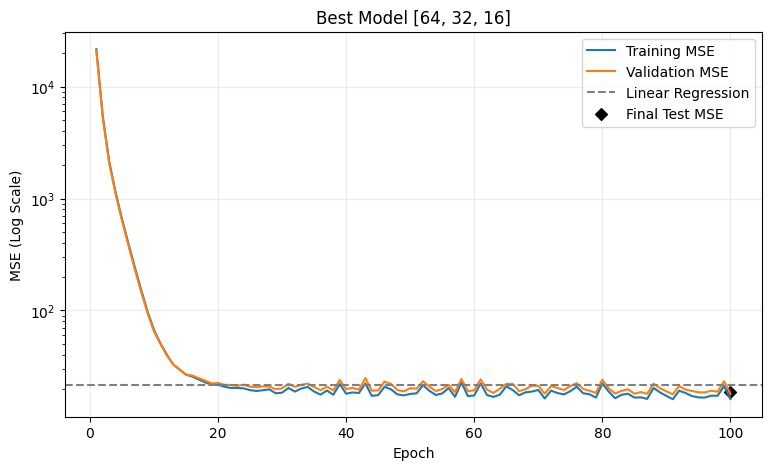

In [30]:

# Best Model Loss Curves
epochs = range(1, len(best_train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, best_train_losses, label="Training MSE")
plt.plot(epochs, best_val_losses, label="Validation MSE")

plt.axhline(linear_val_mse, color="gray", linestyle="--",
            label="Linear Regression")

plt.scatter(len(best_train_losses), test_mse,
            color="black", marker="D", label="Final Test MSE")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (Log Scale)")
plt.title("Best Model [64, 32, 16]")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
